# 04 - SVM experiment: 22 features

**Aim:** evaluate 20 amino-acid fractions and two Kyte–Doolittle profile summaries using the fixed nested-CV protocol.

We copied the workflow from [04 - SVM method](../../04_svm_method.ipynb), retaining the prepared sequences, saved folds, RF settings and fixed 27-candidate search. This experiment has its own feature caches, figures and tables under `results/` beside this notebook.

**Materials**
- `04 - Methods - SVM.pdf` (slides 30–41).
- `04_feature_extraction_hydrophobicity.ipynb` (A.1–A.5 and B.4).
- `04_SVM-sklearn_revised.ipynb` (sections 1–3 and 7).
- [03 - Von Heijne method](../../03_von_heijne_method.ipynb) (PSWM fitting/scoring and reporting).
- [Feature notes](../../../docs/04_feature_candidates.md).

**Status:** five-fold evaluation, figures and observations completed. We used Conda `LB2`. Run from this notebook's folder. The benchmarking split remains reserved.


## Experiment setup

The predictor matrix contains 22 features: 22 sequence descriptors. RF ranking, scaling and SVM fitting use only the current training subset. We retain the original five folds and run all five outer rounds from scratch in 5.3.

The grid uses k = [6, 11, 22], C = 1, 4 and 16, and gamma = 0.5/k, 1/k and 2/k: 27 combinations per outer round. The sequence cache is local to this experiment. Results are written only inside this experiment's `results/` folder.


## 0. Data loading

We kept paths relative to this experiment folder and the Conda `LB2` kernel used in the main notebook.


### 0.1 Imports and paths

We reused the libraries from the main SVM notebook. Prepared inputs are read from `../../../data/prepared`; tables and figures are saved to local `results/tables` and `results/figures` folders.

**Similar code:** main 04 section 0.1; imports from `04_SVM-sklearn_revised.ipynb`.


In [1]:
# Imports follow section 0 in 04_SVM-sklearn_revised.ipynb.
# Path handling follows section 0 in 03_von_heijne_method.ipynb.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Text progress bars work without Jupyter widgets.
from tqdm import tqdm

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    matthews_corrcoef,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
)

# These paths and plot settings follow section 0 in 03_von_heijne_method.ipynb.
input_dir = Path("../../../data/prepared")
table_dir = Path("results/tables")
figure_dir = Path("results/figures")

table_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)

sns.set_theme()


### 0.2 Load the prepared proteins

**Implemented and executed.**

We reused the FASTA reader and accession mapping from 03. The TSV files provide the metadata, and the matching FASTA files provide the sequences. We attached each sequence by accession and assigned label 1 to SP and 0 to NO_SP. The prepared inputs contain 8,146 training proteins and 2,038 benchmarking proteins.

We kept the split and fold assignments from 02b. Cross-validation will use `data`, containing the training proteins; `benchmarking_data` will remain separate. Fold identifiers stay 1–5, with missing fold values allowed for benchmarking.

**Similar code:** 03 section 1.1 supplies this loader. The SVM example section 1 uses a random split of another dataset; we retained our prepared partitions instead.


In [2]:
# This reader is reused from section 1.1 in 03_von_heijne_method.ipynb.
def read_fasta(fasta_path):
    sequences = {}
    with open(fasta_path, encoding="utf-8") as fasta_in:
        for line in fasta_in:
            line = line.strip()
            if line.startswith(">"):
                accession = line[1:].split()[0]
                sequences[accession] = ""
            elif line:
                sequences[accession] += line
    return sequences


# TSV/FASTA loading and accession mapping also follow section 1.1 in that notebook.
positive_data = pd.read_csv(
    input_dir / "positive_dataset.tsv", sep="\t", dtype={"cv_fold": "Int64"}
)
negative_data = pd.read_csv(
    input_dir / "negative_dataset.tsv", sep="\t", dtype={"cv_fold": "Int64"}
)
positive_sequences = read_fasta(input_dir / "positive_dataset.fasta")
negative_sequences = read_fasta(input_dir / "negative_dataset.fasta")

positive_data["sequence"] = positive_data["accession"].map(positive_sequences)
negative_data["sequence"] = negative_data["accession"].map(negative_sequences)
positive_data["label"] = 1
negative_data["label"] = 0

# Keep the saved partitions, as in 03 section 1.1; no random split from the SVM example.
prepared_data = pd.concat([positive_data, negative_data], ignore_index=True)
data = prepared_data[prepared_data["split"] == "training"].copy()
benchmarking_data = prepared_data[prepared_data["split"] == "benchmarking"].copy()

print("Training proteins:", len(data))
print("Benchmarking proteins:", len(benchmarking_data))


Training proteins: 8146
Benchmarking proteins: 2038


## 1. Common feature definitions

We separated fixed choices from quantities learned in each training subset. The composition length n will be learned from positive training proteins; it is not a fixed 90-residue window (slides 30 and 36–40).


### 1.1 Estimate n from the current training subset

**Implemented and executed.**

We defined `get_n(train_data)` to estimate the composition length from the positive proteins in the supplied training subset (slides 30 and 40). Their `cleavage_pos` gives the last SP residue and therefore the annotated SP length.

We chose to round a half-integer median upward so n can be used for sequence slicing. This is our convention; the slides do not specify a rounding rule.

The function will be called separately for each three-fold inner-training set and again for the four-fold outer-training refit. The resulting n will also be used for that split's validation or test proteins. `cleavage_pos` contributes only to this training estimate, not to the predictor matrix.

**Similar code:** neither practical notebook includes this helper. Slide 40 specifies the calculation, and 02c establishes the meaning of `cleavage_pos`.


In [3]:
# This helper implements the training-only median in slides 30 and 40 of
# 04 - Methods - SVM.pdf; neither practical example contains an equivalent function.
def get_n(train_data):
    sp_lengths = train_data.loc[train_data["label"] == 1, "cleavage_pos"]
    median_length = sp_lengths.median()
    # Rounding upward is our project convention, not a rule from the examples.
    return int(np.ceil(median_length))


### 1.2 Fixed feature settings and residue policy

We retained the Kyte–Doolittle scale from Biopython, the first 40 residues and complete windows of 5, following slides 32–34. Unknown positions are preserved; each window averages its known residue values, and summaries ignore missing windows. Composition excludes non-canonical residues from its denominator. These fixed settings are separate from n, which is derived from current training positives.

**Similar code:** main 04 section 1.2; setup and A.1–A.5 of the hydrophobicity notebook.


In [4]:
# Scale lookup follows setup and A.1 in 04_feature_extraction_hydrophobicity.ipynb.
from Bio.SeqUtils.ProtParamData import kd

hydropathy_scale = kd
# Shared alphabet for our composition extractor; not supplied by the hydropathy example.
aa_alphabet = list("ACDEFGHIKLMNPQRSTVWY")

# Region and window follow the starting example on slide 34 of 04 - Methods - SVM.pdf.
hydropathy_length = 40
hydropathy_window = 5


## 2. Feature extraction

This experiment uses 20 amino-acid fractions and two Kyte–Doolittle profile summaries. The sequence extractor returns 22 columns. The definitions and calculations follow the main notebook.


### 2.1 N-terminal amino-acid composition

We reused the 20 canonical-residue fractions over the first n positions, ordered as `ACDEFGHIKLMNPQRSTVWY`. Unknown residues are excluded from the denominator; a segment with no canonical residues gives missing values. The function receives n and never reads cleavage annotations.

The table below reproduces the published n = 21 example from slide 30 and displays all 20 amino acids. For CV, only the training positives determine n.

**Similar code:** main 04 section 2.1, based on the counting in 02c section 5.2 and the vector in SVM slide 30.


In [5]:
composition_feature_names = [f"aa_fraction_{amino_acid}" for amino_acid in aa_alphabet]


# This function adapts the counting in section 5.2 of 02c_data_analysis.ipynb
# to individual proteins, producing the vector defined on slide 30 of the SVM slides.
def amino_acid_composition(sequence, n):
    """Fractions of the canonical residues within the first n positions."""
    counts = dict.fromkeys(aa_alphabet, 0)
    observed = 0
    for residue in sequence[:n]:
        if residue in counts:
            counts[residue] += 1
            observed += 1
    if observed == 0:
        return {name: np.nan for name in composition_feature_names}
    return {
        f"aa_fraction_{amino_acid}": counts[amino_acid] / observed
        for amino_acid in aa_alphabet
    }


# This sequence and n=21 reproduce the worked example on slide 30 of 04 - Methods - SVM.pdf.
slide_example = amino_acid_composition("MRFLAATFLLLALSTAAQAEPQF", 21)
composition_table = pd.DataFrame(
    [[slide_example[f"aa_fraction_{amino_acid}"] for amino_acid in aa_alphabet]],
    columns=aa_alphabet,
    index=["Fraction"],
)

print("N-terminal amino acid composition for slide example:")

with pd.option_context("display.max_columns", 20):
    display(composition_table.round(2))

print("Fractions sum to:", round(sum(slide_example.values()), 12))


N-terminal amino acid composition for slide example:


,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
Fraction,0.29,0.0,0.0,0.05,0.1,0.0,0.0,0.0,0.0,0.24,0.05,0.0,0.05,0.05,0.05,0.05,0.1,0.0,0.0,0.0


Fractions sum to: 1.0


### 2.2 Hydropathy profile and summaries

We reused the complete-window KD profile from the main notebook: first 40 residues, window 5, averaging known values without shifting unknown positions. Its maximum and mean form the two hydropathy descriptors. Profile means weight interior residues more often than edge residues because they occur in more windows.

The cell compares our calculation against `ProteinAnalysis.protein_scale` on canonical sequences and demonstrates the all-unknown policy. The comparison outputs were generated in this run.

**Similar code:** main 04 section 2.2; A.1–A.3, A.5 and B.4 of `04_feature_extraction_hydrophobicity.ipynb`.


In [6]:
hydropathy_feature_names = [
    f"hydropathy_max_w{hydropathy_window}",
    f"hydropathy_profile_mean_w{hydropathy_window}",
]


# This function combines A.1 (residue values) and A.2 (window_profile) in
# 04_feature_extraction_hydrophobicity.ipynb, with the unknown-residue policy from A.5.
def scale_profile(sequence, scale, window, length):
    """Complete-window means for a residue scale, retaining unknown positions."""
    # Similar to A.1: look up one scale value per residue, retaining unknown positions.
    values = [
        scale.get(residue, np.nan)
        for residue in sequence[:length]
    ]
    profile = []
    # Similar to window_profile in A.2: slide only complete windows along the sequence.
    for start in range(len(values) - window + 1):
        # Adapted from A.5: average known residues, without shrinking the end windows.
        window_values = [
            value
            for value in values[start : start + window]
            if not np.isnan(value)
        ]
        profile.append(float(np.mean(window_values)) if window_values else np.nan)
    return profile


# KD wrapper around the shared A.2-style loop; existing feature functions keep
# the same interface and fixed settings from SVM slide 34.
def hydropathy_profile(sequence):
    """Complete-window KD profile over the fixed N-terminal region."""
    return scale_profile(sequence, hydropathy_scale, hydropathy_window, hydropathy_length)


# This function follows profile aggregation in B.4 of
# 04_feature_extraction_hydrophobicity.ipynb and the max/mean pair on SVM slide 34.
def hydropathy_features(sequence):
    """Maximum and mean of the non-missing window values of the profile."""
    profile = [value for value in hydropathy_profile(sequence) if not np.isnan(value)]
    if not profile:
        return {name: np.nan for name in hydropathy_feature_names}
    return dict(zip(hydropathy_feature_names, [max(profile), float(np.mean(profile))]))


# This comparison follows A.3 in 04_feature_extraction_hydrophobicity.ipynb:
# compare our explicit loop with ProteinAnalysis.protein_scale on canonical sequences.
from Bio.SeqUtils.ProtParam import ProteinAnalysis

canonical_sequences = [
    sequence
    for sequence in data["sequence"]
    if set(sequence[:hydropathy_length]) <= set(aa_alphabet)
]
largest_difference = max(
    abs(ours - reference)
    for sequence in canonical_sequences[:300]
    for ours, reference in zip(
        hydropathy_profile(sequence),
        ProteinAnalysis(sequence[:hydropathy_length]).protein_scale(
            hydropathy_scale, hydropathy_window
        ),
    )
)

print(f"Canonical N-termini: {len(canonical_sequences)} of {len(data)} training proteins")
print(f"Largest difference from protein_scale (first 300): {largest_difference:.1e}")
print("Profile values per 40-residue segment:", len(hydropathy_profile("A" * 40)))
# Project check for the missing-value behavior motivated by A.5.
print("All-unknown segment:", hydropathy_features("X" * 40))


Canonical N-termini: 8144 of 8146 training proteins
Largest difference from protein_scale (first 300): 8.9e-16
Profile values per 40-residue segment: 36
All-unknown segment: {'hydropathy_max_w5': nan, 'hydropathy_profile_mean_w5': nan}


### 2.3 Assemble the feature extractor and catalog

`extract_features(proteins, n)` returns the 22 sequence-only descriptors in a shared column order. `feature_names` contains all 22 predictor names. The catalog documents the complete feature set.

The extraction below is a sequence-only demonstration. Nested CV derives n separately from each training subset.

**Similar code:** main 04 section 2.7; the profile summaries follow B.4 of the hydrophobicity notebook.


In [7]:
# Sequence-only groups follow the selected feature set from the main notebook.
sequence_feature_names = (
    composition_feature_names + hydropathy_feature_names
)
feature_names = sequence_feature_names.copy()
D = len(feature_names)


# Same sequence extractor as main 04 section 2.7, with the selected groups.
def extract_features(proteins, n):
    records = []
    for sequence in tqdm(proteins["sequence"], desc="Extracting features", unit="protein"):
        record = {}
        record.update(amino_acid_composition(sequence, n))
        record.update(hydropathy_features(sequence))
        records.append(record)
    features = pd.DataFrame(
        records, index=pd.Index(proteins["accession"], name="accession")
    )
    return features[sequence_feature_names]


feature_catalog = pd.DataFrame(
    [
        {
            "feature": f"aa_fraction_{amino_acid}",
            "definition": f"Fraction of the canonical residues that are {amino_acid}",
            "region": "first n residues (n estimated from the training positives)",
            "scale": "none (residue counts)",
            "window": pd.NA,
            "aggregation": "fraction",
            "unit": "fraction of canonical residues",
        }
        for amino_acid in aa_alphabet
    ]
    + [
        {
            "feature": hydropathy_feature_names[0],
            "definition": "Maximum of the Kyte-Doolittle window profile",
            "region": f"first {hydropathy_length} residues (fixed)",
            "scale": "Kyte-Doolittle",
            "window": hydropathy_window,
            "aggregation": "maximum",
            "unit": "hydropathy index",
        },
        {
            "feature": hydropathy_feature_names[1],
            "definition": "Mean of the Kyte-Doolittle window profile",
            "region": f"first {hydropathy_length} residues (fixed)",
            "scale": "Kyte-Doolittle",
            "window": hydropathy_window,
            "aggregation": "mean",
            "unit": "hydropathy index",
        },
    ]
)

# Sequence-only demonstration; supervised PSWM scores are added only after splitting.
example_features = extract_features(data, get_n(data))
print("Sequence-only example:", example_features.shape)
print("Missing values:", int(example_features.isna().sum().sum()))
print("Classifier features:", D)
feature_catalog


Extracting features: 100%|██████████| 8146/8146 [00:03<00:00, 2496.62protein/s]


Sequence-only example: (8146, 22)
Missing values: 0
Classifier features: 22


,feature,definition,region,scale,window,aggregation,unit
0,aa_fraction_A,Fraction of the canonical residues that are A,first n residues (n estimated from the trainin...,none (residue counts),<NA>,fraction,fraction of canonical residues
1,aa_fraction_C,Fraction of the canonical residues that are C,first n residues (n estimated from the trainin...,none (residue counts),<NA>,fraction,fraction of canonical residues
2,aa_fraction_D,Fraction of the canonical residues that are D,first n residues (n estimated from the trainin...,none (residue counts),<NA>,fraction,fraction of canonical residues
3,aa_fraction_E,Fraction of the canonical residues that are E,first n residues (n estimated from the trainin...,none (residue counts),<NA>,fraction,fraction of canonical residues
4,aa_fraction_F,Fraction of the canonical residues that are F,first n residues (n estimated from the trainin...,none (residue counts),<NA>,fraction,fraction of canonical residues
5,aa_fraction_G,Fraction of the canonical residues that are G,first n residues (n estimated from the trainin...,none (residue counts),<NA>,fraction,fraction of canonical residues
6,aa_fraction_H,Fraction of the canonical residues that are H,first n residues (n estimated from the trainin...,none (residue counts),<NA>,fraction,fraction of canonical residues
7,aa_fraction_I,Fraction of the canonical residues that are I,first n residues (n estimated from the trainin...,none (residue counts),<NA>,fraction,fraction of canonical residues
8,aa_fraction_K,Fraction of the canonical residues that are K,first n residues (n estimated from the trainin...,none (residue counts),<NA>,fraction,fraction of canonical residues
9,aa_fraction_L,Fraction of the canonical residues that are L,first n residues (n estimated from the trainin...,none (residue counts),<NA>,fraction,fraction of canonical residues


### 2.4 Reuse training feature tables on demand

The cache loads or creates the sequence-only table for the requested n and returns accessions in their supplied order. When another table is available, fixed-region descriptors are reused and only composition is recalculated. Files and memory caches belong to this experiment; remove the files and rerun this cell if the sequence data or definitions change.

Each split still derives n from its own training positives. RF, scaling and SVM fitting remain specific to that training subset.

**Similar code:** dynamic caching in main 04 section 2.8.


In [8]:
# Cache the sequence-only features from sections 2.1-2.3 on demand.
# TSV paths and export follow the project conventions used in 03 section 5.
feature_cache_dir = table_dir / "feature_cache"
feature_cache_dir.mkdir(parents=True, exist_ok=True)
fixed_feature_names = sequence_feature_names[len(composition_feature_names):]
feature_tables = {}


# Each CV split requests its own n, as required by SVM slide 40.
def get_cached_features(proteins, n):
    if n not in feature_tables:
        cache_path = feature_cache_dir / f"training_features_n{n}.tsv"
        if cache_path.exists():
            print("Loading feature table:", cache_path)
            features = pd.read_csv(
                cache_path, sep="\t", index_col="accession", float_precision="round_trip"
            )
        else:
            print("Preparing feature table:", cache_path)
            reference_features = next(iter(feature_tables.values()), None)
            if reference_features is None:
                reference_path = next(feature_cache_dir.glob("training_features_n*.tsv"), None)
                if reference_path is not None:
                    reference_features = pd.read_csv(
                        reference_path, sep="\t", index_col="accession",
                        float_precision="round_trip"
                    )

            if reference_features is None:
                features = extract_features(data, n)
            else:
                records = [
                    amino_acid_composition(sequence, n)
                    for sequence in tqdm(
                        data["sequence"], desc=f"Composition (n={n})", unit="protein"
                    )
                ]
                composition = pd.DataFrame(
                    records, index=pd.Index(data["accession"], name="accession")
                )
                features = pd.concat(
                    [composition, reference_features[fixed_feature_names]], axis=1
                )[sequence_feature_names]
            features.to_csv(cache_path, sep="\t")
            print("Table saved in:", cache_path)

        feature_tables[n] = features

    return feature_tables[n].loc[proteins["accession"], sequence_feature_names].copy()


## 3. Random Forest selection and SVM helpers

We followed the order in slides 35–36: extract features, rank them with Random Forest, keep top-k, standardize selected columns, and train an RBF SVM. Person 3 prepared the helpers, section 3.5 shows how they work together, and Person 4 used them inside CV.


### 3.1 Fit a Random Forest ranking

We retained `rank_features(X_train, y_train)` with 500 trees and `random_state = 0`. The function returns feature indices, names and importances in descending importance order. It is fitted separately for each current training subset and reused across candidate k values. Inner-fold bars track fitting without tree logs.

**Similar code:** main 04 section 3.1 and RF selection on SVM slide 35.


In [9]:
# This function follows RF fitting and importance ranking on slide 35 of
# 04 - Methods - SVM.pdf; names and sorted importances are added for reporting.
def rank_features(X_train, y_train):
    rf = RandomForestClassifier(
        n_estimators=500, random_state=0
    )
    rf.fit(X_train, y_train)

    importances = rf.feature_importances_
    ranking = np.argsort(importances)[::-1]
    ranked_features = X_train.columns[ranking].tolist()
    ranked_importances = importances[ranking]

    return ranking, ranked_features, ranked_importances


### 3.2 Build the coupled parameter grid

We retained the fixed grid from slide 38: k = ceil(D/4), ceil(D/2) and D; C = 1, 4 and 16; gamma = 0.5/k, 1/k and 2/k. Here D = 22, so k = [6, 11, 22]. The grid contains 27 tuples `(k, C, gamma)`, with gamma factor printed separately. Exact score ties retain the first tuple in grid order.

**Similar code:** main 04 section 3.2 and SVM slides 38–40. No grid extensions are used.


In [10]:
# These candidates follow the minimal grid on slide 38 of 04 - Methods - SVM.pdf.
k_values = sorted({int(np.ceil(D / 4)), int(np.ceil(D / 2)), D})
C_values = [1, 4, 16]
gamma_factors = [0.5, 1, 2]

parameter_grid = []
for k in k_values:
    for C in C_values:
        for factor in gamma_factors:
            gamma = factor / k
            parameter_grid.append((k, C, gamma))

print("Feature counts:", k_values)
print("Regularization constants:", C_values)
print("Gamma factors:", gamma_factors)
print("Parameter combinations:", len(parameter_grid))

for k, C, gamma in parameter_grid:
    print(f"Parameters: k={k}, C={C}, gamma={gamma:.4f}, gamma factor={gamma * k:g}")


Feature counts: [6, 11, 22]
Regularization constants: [1, 4, 16]
Gamma factors: [0.5, 1, 2]
Parameter combinations: 27
Parameters: k=6, C=1, gamma=0.0833, gamma factor=0.5
Parameters: k=6, C=1, gamma=0.1667, gamma factor=1
Parameters: k=6, C=1, gamma=0.3333, gamma factor=2
Parameters: k=6, C=4, gamma=0.0833, gamma factor=0.5
Parameters: k=6, C=4, gamma=0.1667, gamma factor=1
Parameters: k=6, C=4, gamma=0.3333, gamma factor=2
Parameters: k=6, C=16, gamma=0.0833, gamma factor=0.5
Parameters: k=6, C=16, gamma=0.1667, gamma factor=1
Parameters: k=6, C=16, gamma=0.3333, gamma factor=2
Parameters: k=11, C=1, gamma=0.0455, gamma factor=0.5
Parameters: k=11, C=1, gamma=0.0909, gamma factor=1
Parameters: k=11, C=1, gamma=0.1818, gamma factor=2
Parameters: k=11, C=4, gamma=0.0455, gamma factor=0.5
Parameters: k=11, C=4, gamma=0.0909, gamma factor=1
Parameters: k=11, C=4, gamma=0.1818, gamma factor=2
Parameters: k=11, C=16, gamma=0.0455, gamma factor=0.5
Parameters: k=11, C=16, gamma=0.0909, gamm

### 3.3 Standardize selected features and fit SVC

**Implemented and executed.**

We defined `fit_svm(X_train, y_train, C, gamma)` following section 3 of the SVM example. It fits a scaler on the supplied training columns, transforms them and trains an RBF SVM with the candidate C and gamma. It returns the fitted scaler and model together.

`predict_svm(X, scaler, model)` applies that same scaler before predicting validation or test labels. Person 4 will pass the top-k columns selected from the current training ranking, keeping the same column order for training and prediction.

**Similar code:** section 3 of `04_SVM-sklearn_revised.ipynb` supplies the scaler, training transformation, SVC fit and test transformation. We wrapped those steps in two functions for reuse in the loops on slide 40 of `04 - Methods - SVM.pdf`.


In [11]:
# These functions wrap the scaling, fitting and prediction steps in section 3
# of 04_SVM-sklearn_revised.ipynb for reuse inside the CV loops.
def fit_svm(X_train, y_train, C, gamma):
    scaler = StandardScaler().fit(X_train)
    model = SVC(C=C, kernel="rbf", gamma=gamma)
    model.fit(scaler.transform(X_train), y_train)
    return scaler, model


def predict_svm(X, scaler, model):
    return model.predict(scaler.transform(X))


### 3.4 Calculate classification metrics

**Implemented and executed.**

We adapted the example's `evaluate` function to return a dictionary with precision, recall, accuracy, MCC and F1, using the same metric names as 03. Class 1 represents signal peptides. We chose zero for undefined precision, recall or F1, for example when a model predicts no positives.

Person 4 will use MCC to compare inner-validation candidates and report all five metrics for each outer test fold. The helpers in section 3 are now prepared for those loops; no model has been fitted by defining them.

**Similar code:** `evaluate` in section 1 of `04_SVM-sklearn_revised.ipynb` calculates the same five metrics. We return the values instead of printing them so the CV loops can save them in tables, as in 03 section 5.


In [12]:
# This function adapts evaluate from section 1 of 04_SVM-sklearn_revised.ipynb:
# return a record for CV tables rather than printing each metric.
def calculate_metrics(y_true, y_pred):
    return {
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
        "mcc": matthews_corrcoef(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }


### 3.5 Worked example on one validation split

**Example executed.** We use folds 1–4 for training and fold 5 for validation to demonstrate the complete pipeline before the inner loop. The training subset supplies n; RF ranking, scaling and SVM fitting use this subset only. Validation sequences use the same fitted transformation. The example compares the 27 candidates and records selection scores, rather than independent test estimates.

**Similar code:** main 04 section 3.5 and SVM slide 40.


In [13]:
# Worked example: four training folds and one validation fold.
# Sections 4-5 will repeat this workflow within nested CV.
demo_train = data[data["cv_fold"] != 5]
demo_validation = data[data["cv_fold"] == 5]

n = get_n(demo_train)

x_train = get_cached_features(demo_train, n)
y_train = x_train.index.map(
    demo_train.set_index("accession")["label"]
).values

x_validation = get_cached_features(demo_validation, n)
y_validation = x_validation.index.map(
    demo_validation.set_index("accession")["label"]
).values

ranking, ranked_features, ranked_importances = rank_features(
    x_train, y_train
)

print("Top 10 ranked features:", ranked_features[:10])
print("Top 10 ranked importances:", ranked_importances[:10])
print("Bottom 10 ranked features:", ranked_features[-10:])
print("Bottom 10 ranked importances:", ranked_importances[-10:])

max_mcc = -np.inf
best_params = None
best_metrics = None
results = []

for k, C, gamma in tqdm(
    parameter_grid, desc="Parameter grid search", unit="combination"
):
    selected_names = ranked_features[:k]
    X_train_k = x_train[selected_names]
    X_validation_k = x_validation[selected_names]

    scaler, model = fit_svm(X_train_k, y_train, C, gamma)
    y_pred = predict_svm(X_validation_k, scaler, model)

    metrics = calculate_metrics(y_validation, y_pred)
    results.append({"k": k, "C": C, "gamma": gamma, **metrics})

    #print(f"Parameters: k={k}, C={C}, gamma={gamma:.4f}")
    #print("Metrics:", metrics)

    if metrics["mcc"] > max_mcc:
        max_mcc = metrics["mcc"]
        best_params = (k, C, gamma)
        best_metrics = metrics

print("Best parameters:", best_params)
print("Best validation metrics:", best_metrics)

results_table = pd.DataFrame(results).sort_values(
    "mcc", ascending=False
)


Loading feature table: results/tables/feature_cache/training_features_n22.tsv
Top 10 ranked features: ['hydropathy_max_w5', 'hydropathy_profile_mean_w5', 'aa_fraction_L', 'aa_fraction_A', 'aa_fraction_R', 'aa_fraction_E', 'aa_fraction_D', 'aa_fraction_V', 'aa_fraction_G', 'aa_fraction_F']
Top 10 ranked importances: [0.23564532 0.20829532 0.13708824 0.04113303 0.03385097 0.03047127
 0.02976797 0.0268979  0.02510301 0.02342095]
Bottom 10 ranked features: ['aa_fraction_I', 'aa_fraction_N', 'aa_fraction_K', 'aa_fraction_T', 'aa_fraction_W', 'aa_fraction_C', 'aa_fraction_Q', 'aa_fraction_Y', 'aa_fraction_M', 'aa_fraction_H']
Bottom 10 ranked importances: [0.02188268 0.01983466 0.01977819 0.01922212 0.01814887 0.01677095
 0.01415531 0.01270004 0.01204016 0.00924787]


Parameter grid search: 100%|██████████| 27/27 [00:09<00:00,  2.80combination/s]

Best parameters: (22, 16, 0.022727272727272728)
Best validation metrics: {'precision': 0.8711656441717791, 'recall': 0.8068181818181818, 'accuracy': 0.9662369551872314, 'mcc': 0.8196978878420824, 'f1': 0.8377581120943953}


**Ranking and feature exploration.** Maximum hydropathy, mean hydropathy and leucine fraction led the worked-example RF ranking. The complete outer-training rankings are plotted in 6.4; their interpretation is based on all five fits rather than only this example.


## 4. Inner model selection

We chose explicit loops from slide 40 so the changing composition length and reused RF ranking are visible. Selection will use the four saved folds available within each outer-training set, with three for training and one for validation.


### 4.1 Select outer and inner subsets

**Implemented and executed.**

We adapted `get_cv_split` from 03 to receive both `test_fold` and `validation_fold`. It returns the three remaining folds as inner training, the chosen inner-validation fold and the held-out outer-test fold. We used `data`, which contains only training proteins, and kept its saved fold identifiers 1–5.

The example below selects fold 1 as outer test and fold 2 as inner validation. The training subset therefore contains folds 3–5. For each outer round, the inner loop will rotate validation through the four folds other than test. The outer refit in section 5 will combine those four folds for training.

**Similar code:** `get_cv_split` in 03 section 1.2 uses the same filtering, but chooses one validation fold automatically. We made that choice explicit to follow the nested subsets in slides 37 and 40 of `04 - Methods - SVM.pdf`.


In [14]:
# Adapted from get_cv_split in 03_von_heijne_method.ipynb:
# validation_fold is explicit for the nested splits in SVM slides 37 and 40.
def get_cv_split(data, test_fold, validation_fold):
    train = data[~data["cv_fold"].isin([test_fold, validation_fold])].copy()
    validation = data[data["cv_fold"] == validation_fold].copy()
    test = data[data["cv_fold"] == test_fold].copy()
    return train, validation, test


fold_ids = sorted(data["cv_fold"].drop_duplicates().tolist())
test_fold = fold_ids[0]
validation_folds = [fold for fold in fold_ids if fold != test_fold]
validation_fold = validation_folds[0]

inner_train, inner_validation, outer_test = get_cv_split(
    data, test_fold, validation_fold
)

print("Outer test fold:", test_fold)
print("Inner validation fold:", validation_fold)
print("Inner training folds:", sorted(inner_train["cv_fold"].unique().tolist()))
print("Inner training proteins:", len(inner_train))
print("Inner validation proteins:", len(inner_validation))
print("Outer test proteins:", len(outer_test))


Outer test fold: 1
Inner validation fold: 2
Inner training folds: [3, 4, 5]
Inner training proteins: 4887
Inner validation proteins: 1629
Outer test proteins: 1630


### 4.2 Prepare each inner-training fit

We prepare four inner splits for the selected outer fold. Each split derives n from its three training folds, retrieves the sequence features, then fits RF on its own training matrix. The held-out outer fold contributes to none of these fits. Matrices and rankings are reused across candidates.

**Similar code:** main 04 section 4.2 and SVM slide 40.


In [15]:
# Like the extraction and ranking block in our section 3.5 example,
# repeated over the inner folds as described in SVM slide 40.
# Sequence features use the cache in section 2.4.
def prepare_inner_fits(data, test_fold):
    folds = sorted(data["cv_fold"].drop_duplicates().tolist())
    validation_folds = [fold for fold in folds if fold != test_fold]
    inner_fits = []

    for validation_fold in tqdm(
        validation_folds, desc="Preparing inner folds", unit="fold", leave=False, position=1,
        mininterval=0.5
    ):
        inner_train, inner_validation, _ = get_cv_split(
            data, test_fold, validation_fold
        )
        n = get_n(inner_train)

        X_train = get_cached_features(inner_train, n)
        X_validation = get_cached_features(inner_validation, n)
        y_train = X_train.index.map(
            inner_train.set_index("accession")["label"]
        ).values
        y_validation = X_validation.index.map(
            inner_validation.set_index("accession")["label"]
        ).values

        _, ranked_features, _ = rank_features(X_train, y_train)
        inner_fits.append({
            "validation_fold": validation_fold,
            "n": n,
            "X_train": X_train,
            "X_validation": X_validation,
            "y_train": y_train,
            "y_validation": y_validation,
            "ranked_features": ranked_features,
        })

    return inner_fits


In [16]:
inner_fits = prepare_inner_fits(data, test_fold)
print("Prepared inner folds:", len(inner_fits))


Prepared inner folds: 4


### 4.3 Score the grid and choose a combination

**Implemented and executed.**

We defined `score_inner_grid` to evaluate each `(k, C, gamma)` combination on the four prepared inner splits. For each split, the function selects its own top-k features, fits a fresh scaler and SVM on inner training, and calculates validation MCC. The function returns one row per candidate and validation fold in `inner_scores`, including the outer-test identifier and n.

The selection below groups the scores by candidate and chooses the highest mean MCC across the four validation folds. We kept the candidate order from 3.2, so `idxmax` retains the first combination if means tie exactly. The initial search contains 27 candidates and therefore 108 SVM fits for this outer round. The progress bar counts individual SVM fits and shows the current k, C, gamma and validation fold. Its remaining-time estimate covers the current batch of candidates. A single SVM fit advances the bar when it finishes. The function definition is in its own cell so progress changes can be loaded without repeating the search.

We restricted selection to the 27 combinations from 3.2 for all rounds. A selected setting may lie at a grid boundary; we retain it within this fixed search rather than adding candidates.

**Similar code:** our worked example in 3.5 supplies feature selection, scaling, fitting and validation. Slides 38–40 of `04 - Methods - SVM.pdf` extend that workflow to averaging the four inner scores and choosing settings before outer evaluation.


In [17]:
# Like the parameter loop in our section 3.5 example, evaluated on
# all four inner splits before selection, following SVM slides 38-40.
# Progress counts individual SVM fits in the current candidate batch.
def score_inner_grid(inner_fits, parameter_grid, test_fold):
    records = []
    with tqdm(
        total=len(parameter_grid) * len(inner_fits),
        desc=f"Test fold {test_fold}: inner SVM", unit="fit", miniters=1,
        leave=False, position=1, mininterval=0.5
    ) as progress:
        for k, C, gamma in parameter_grid:
            for inner_fit in inner_fits:
                progress.set_postfix(
                    k=k, C=C, gamma=f"{gamma:.3g}", val=inner_fit["validation_fold"]
                )
                selected_names = inner_fit["ranked_features"][:k]
                X_train_k = inner_fit["X_train"][selected_names]
                X_validation_k = inner_fit["X_validation"][selected_names]

                scaler, model = fit_svm(
                    X_train_k, inner_fit["y_train"], C, gamma
                )
                y_pred = predict_svm(X_validation_k, scaler, model)
                mcc = matthews_corrcoef(inner_fit["y_validation"], y_pred)
                records.append({
                    "test_fold": test_fold,
                    "validation_fold": inner_fit["validation_fold"],
                    "n": inner_fit["n"],
                    "k": k,
                    "C": C,
                    "gamma": gamma,
                    "mcc": mcc,
                })
                progress.update(1)

    return pd.DataFrame(records)


In [18]:
inner_scores = score_inner_grid(inner_fits, parameter_grid, test_fold)
mean_inner_scores = (
    inner_scores.groupby(["k", "C", "gamma"], sort=False, as_index=False)["mcc"]
    .mean()
    .rename(columns={"mcc": "mean_mcc"})
)
best_row = mean_inner_scores.loc[mean_inner_scores["mean_mcc"].idxmax()]
best_params = (int(best_row["k"]), float(best_row["C"]), float(best_row["gamma"]))

print("Best parameters:", best_params)
print("Best mean validation MCC:", best_row["mean_mcc"])
print("Selected gamma factor:", best_params[0] * best_params[2])
mean_inner_scores.sort_values("mean_mcc", ascending=False)


Best parameters: (22, 4.0, 0.022727272727272728)
Best mean validation MCC: 0.7886151172654641
Selected gamma factor: 0.5


,k,C,gamma,mean_mcc
21,22,4,0.022727,0.788615
18,22,1,0.022727,0.784667
19,22,1,0.045455,0.782181
22,22,4,0.045455,0.773346
20,22,1,0.090909,0.771896
24,22,16,0.022727,0.768497
23,22,4,0.090909,0.766553
12,11,4,0.045455,0.765742
10,11,1,0.090909,0.760282
9,11,1,0.045455,0.759919


**Inner-search heatmaps**

We arranged the mean validation scores as one heatmap per k, stacked vertically for readable labels and annotations, with C in rows and the gamma factor (`gamma × k`) in columns. All panels share the same color scale over the evaluated scores. Each cell shows the MCC averaged across the four inner folds; the red outline marks the selected combination. This view helps compare settings and inspect the search boundaries before the outer refit.

**Similar code:** we adapted the annotated Seaborn heatmap and PDF export from 03 section 2.3 to the parameter table in 4.3. This is our visualization of the inner search described in SVM slides 38–40.


Plot saved in: results/figures/4_3_inner_search_test_fold_1.pdf


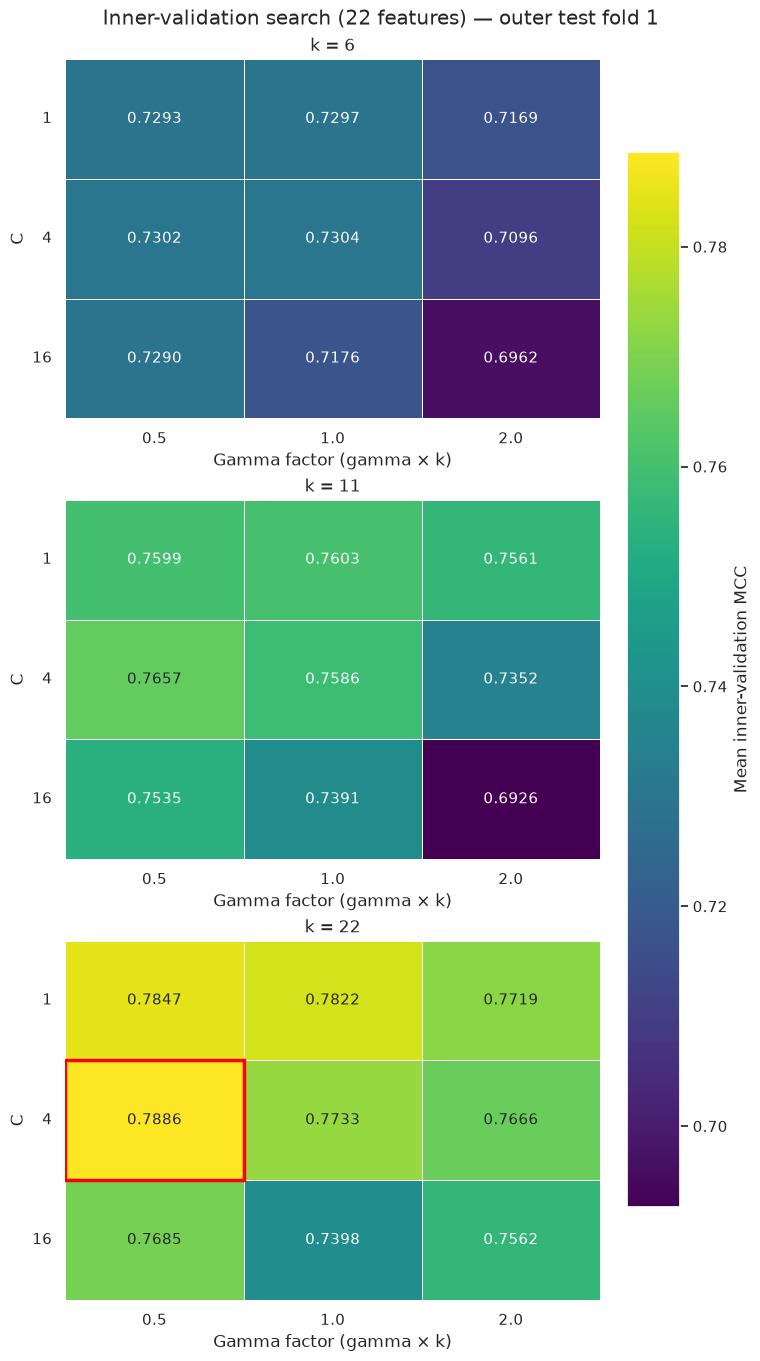

In [19]:
# Annotated heatmaps and PDF saving follow 03 section 2.3.
# Here the plotted values are the mean inner-validation MCC from section 4.3.
plot_scores = mean_inner_scores.copy()
plot_scores["gamma_factor"] = (plot_scores["gamma"] * plot_scores["k"]).round(6)
plot_k_values = sorted(plot_scores["k"].unique())

fig, axes = plt.subplots(
    len(plot_k_values), 1, figsize=(7.5, 4.5 * len(plot_k_values)),
    squeeze=False, layout="constrained"
)
for ax, k in zip(axes.flat, plot_k_values):
    score_matrix = (
        plot_scores[plot_scores["k"] == k]
        .pivot(index="C", columns="gamma_factor", values="mean_mcc")
        .sort_index()
        .sort_index(axis=1)
    )
    sns.heatmap(
        score_matrix, ax=ax, annot=True, fmt=".4f", cmap="viridis",
        vmin=plot_scores["mean_mcc"].min(), vmax=plot_scores["mean_mcc"].max(),
        linewidths=0.5, cbar=False, annot_kws={"fontsize": 11}
    )
    ax.set_title(f"k = {k}")
    ax.set_xlabel("Gamma factor (gamma × k)")
    ax.set_ylabel("C")
    ax.tick_params(axis="both", labelrotation=0)

    if k == best_params[0]:
        row = score_matrix.index.get_loc(best_params[1])
        column = score_matrix.columns.get_loc(round(best_params[2] * k, 6))
        ax.add_patch(plt.Rectangle(
            (column, row), 1, 1, fill=False, edgecolor="red", linewidth=2.5
        ))

fig.colorbar(
    axes[0, 0].collections[0], ax=axes.ravel().tolist(),
    label="Mean inner-validation MCC", shrink=0.85
)
fig.suptitle(f"Inner-validation search (22 features) — outer test fold {test_fold}")
figure_path = figure_dir / f"4_3_inner_search_test_fold_{test_fold}.pdf"
fig.savefig(figure_path, format="pdf", bbox_inches="tight")
print("Plot saved in:", figure_path)
plt.show()


## 5. Outer refit and evaluation

The evaluation uses the saved five folds, keeping each test fold outside inner selection and outer-training fitting. The five outer rounds were completed.


### 5.1 Refit on the four outer-training folds

We derive n again from the four training folds, build the feature matrices and fit a new RF ranking, scaler and SVM with the selected settings. The held-out test fold is transformed using these training-fitted objects. The function definition is separate from its example call.

**Similar code:** main 04 section 5.1 and the outer refit in SVM slide 40.


In [20]:
# Refit on four outer-training folds, following the refit block in SVM slide 40.
# Ranking follows section 3.5; scaling/SVC use section 3.3.
# Sequence features use the cache in section 2.4.
def refit_outer_model(data, test_fold, best_params):
    outer_train = data[data["cv_fold"] != test_fold].copy()
    outer_test = data[data["cv_fold"] == test_fold].copy()
    k, C, gamma = best_params
    n = get_n(outer_train)

    X_train = get_cached_features(outer_train, n)
    X_test = get_cached_features(outer_test, n)
    y_train = X_train.index.map(
        outer_train.set_index("accession")["label"]
    ).values
    y_test = X_test.index.map(
        outer_test.set_index("accession")["label"]
    ).values

    _, ranked_features, ranked_importances = rank_features(X_train, y_train)
    selected_names = ranked_features[:k]
    scaler, model = fit_svm(X_train[selected_names], y_train, C, gamma)

    return {
        "test_fold": test_fold,
        "n": n,
        "k": k,
        "C": C,
        "gamma": gamma,
        "selected_names": selected_names,
        "selected_importances": ranked_importances[:k],
        "X_test": X_test[selected_names],
        "y_test": y_test,
        "scaler": scaler,
        "model": model,
    }


In [21]:
outer_fit = refit_outer_model(data, test_fold, best_params)
print("Outer test fold:", outer_fit["test_fold"])
print("Composition length:", outer_fit["n"])
print("Selected feature count:", outer_fit["k"])


Outer test fold: 1
Composition length: 22
Selected feature count: 22


### 5.2 Predict and record one external fold

**Implemented and executed.**

We defined `evaluate_outer_model(outer_fit)` to predict the held-out fold with the scaler and SVM fitted in 5.1. It calculates precision, recall, accuracy, MCC and F1, and returns the round's settings/metrics, accession-level predictions and selected-feature ranks/importances.

The call below prepares `cv_per_round`, `cv_predictions` and `selected_features` for the current outer fold. These tables describe the single-round example; 5.3 resets them and runs all five rounds. Test accessions and labels follow the row order of `outer_fit["X_test"]`, and importances retain the new outer-training RF ranking.

**Similar code:** prediction and metrics reuse our helpers from 3.3–3.4, based on sections 1 and 3 of `04_SVM-sklearn_revised.ipynb`. Slides 39–41 of `04 - Methods - SVM.pdf` specify external evaluation and reporting; the result records follow the table structure used in 03 section 5.


In [22]:
# Prediction and metrics reuse sections 3.3-3.4, as in the section 3.5 example.
# Here they evaluate the held-out outer fold, following SVM slides 39-41.
def evaluate_outer_model(outer_fit):
    y_pred = predict_svm(
        outer_fit["X_test"], outer_fit["scaler"], outer_fit["model"]
    )
    metrics = calculate_metrics(outer_fit["y_test"], y_pred)
    round_result = {
        "test_fold": outer_fit["test_fold"],
        "n": outer_fit["n"],
        "selected_k": outer_fit["k"],
        "C": outer_fit["C"],
        "gamma": outer_fit["gamma"],
        **metrics,
    }
    round_predictions = pd.DataFrame({
        "accession": outer_fit["X_test"].index,
        "test_fold": outer_fit["test_fold"],
        "label": outer_fit["y_test"],
        "prediction": y_pred,
    })
    round_features = pd.DataFrame({
        "test_fold": outer_fit["test_fold"],
        "feature": outer_fit["selected_names"],
        "rank": range(1, len(outer_fit["selected_names"]) + 1),
        "importance": outer_fit["selected_importances"],
    })
    return round_result, round_predictions, round_features


round_result, round_predictions, round_features = evaluate_outer_model(outer_fit)
cv_per_round = pd.DataFrame([round_result])
cv_predictions = round_predictions.copy()
selected_features = round_features.copy()

print("Completed outer rounds:", len(cv_per_round))
print("Test predictions:", len(cv_predictions))
cv_per_round


Completed outer rounds: 1
Test predictions: 1630


,test_fold,n,selected_k,C,gamma,precision,recall,accuracy,mcc,f1
0,1,22,22,4.0,0.022727,0.871345,0.841808,0.969325,0.839314,0.856322


### 5.3 Complete all five outer rounds

**Implemented and executed.**

We combined the helpers from 4.1–5.2 to run all five outer rounds from scratch. Each execution resets the four result tables and includes fold 1 again; the single-round example in 5.2 remains separate from this complete evaluation. Each round reads n-specific feature rows from the tables in 2.4 for its own four inner splits, starts with the original ranges from 3.2, selects settings, refits on four folds and evaluates its held-out fold.

We defined `select_inner_model` to evaluate exactly the 27 combinations from 3.2 on the four inner splits: 108 SVM fits per outer round. It selects the highest mean validation MCC, keeping the first candidate in grid order for exact ties. The grid stays fixed even when a selected value is at a boundary. Selection finishes before outer refitting and prediction.

The loop adds metrics to `cv_per_round`, accession-level predictions to `cv_predictions`, selected-feature records to `selected_features` and all evaluated inner scores to `inner_scores`. It updates the tables after each completed round. When all five rounds finish, the prediction table should cover the 8,146 training proteins once each. Section 6 will summarize and export these results.

**Similar code:** slide 40 provides the nested workflow and slide 38 provides the original grid. We reused our preparation/scoring functions from 4.2–4.3 and refit/evaluation helpers from 5.1–5.2; per-round collection follows 03 section 5.

The outer bar counts completed rounds and shows the active fold and phase. Temporary bars show progress through the four RF fits and the 108 inner SVM fits, then disappear. Each completed fold leaves one line with its selected k, C, gamma factor and test MCC.


In [23]:
# Repeat the fixed 27-candidate inner search from section 4.3.
# Candidate averaging follows SVM slides 38-40.
def select_inner_model(inner_fits, test_fold):
    search_scores = score_inner_grid(inner_fits, parameter_grid, test_fold)
    mean_scores = (
        search_scores.groupby(["k", "C", "gamma"], sort=False, as_index=False)["mcc"]
        .mean()
        .rename(columns={"mcc": "mean_mcc"})
    )
    best_row = mean_scores.loc[mean_scores["mean_mcc"].idxmax()]
    best_params = (int(best_row["k"]), float(best_row["C"]), float(best_row["gamma"]))
    return best_params, search_scores


# Run all five outer rounds from scratch, following SVM slide 40.
# Per-round table collection follows section 5 of the 03 notebook.
cv_per_round = pd.DataFrame()
cv_predictions = pd.DataFrame()
selected_features = pd.DataFrame()
inner_scores = pd.DataFrame()

with tqdm(fold_ids, desc="Outer rounds", unit="fold", miniters=1, position=0) as outer_progress:
    for next_test_fold in outer_progress:
        outer_progress.set_postfix(test=next_test_fold, stage="features/RF")
        fold_inner_fits = prepare_inner_fits(data, next_test_fold)
        outer_progress.set_postfix(test=next_test_fold, stage="inner search")
        fold_best_params, fold_inner_scores = select_inner_model(
            fold_inner_fits, next_test_fold
        )
        outer_progress.set_postfix(test=next_test_fold, stage="outer refit")
        fold_outer_fit = refit_outer_model(data, next_test_fold, fold_best_params)
        outer_progress.set_postfix(test=next_test_fold, stage="test prediction")
        fold_result, fold_predictions, fold_features = evaluate_outer_model(fold_outer_fit)

        cv_per_round = pd.concat([cv_per_round, pd.DataFrame([fold_result])], ignore_index=True)
        cv_predictions = pd.concat([cv_predictions, fold_predictions], ignore_index=True)
        selected_features = pd.concat([selected_features, fold_features], ignore_index=True)
        inner_scores = pd.concat([inner_scores, fold_inner_scores], ignore_index=True)
        k, C, gamma = fold_best_params
        outer_progress.write(
            f"Fold {next_test_fold}: k={k}, C={C:g}, gamma factor={gamma * k:g}, "
            f"MCC={fold_result['mcc']:.3f}"
        )

cv_per_round = cv_per_round.sort_values("test_fold").reset_index(drop=True)
print("Completed outer rounds:", len(cv_per_round))
print("Test predictions:", len(cv_predictions))
cv_per_round


Outer rounds:  20%|██        | 1/5 [00:34<02:17, 34.28s/fold, stage=features/RF, test=2]    

Fold 1: k=22, C=4, gamma factor=0.5, MCC=0.839


Loading feature table: results/tables/feature_cache/training_features_n21.tsv


Outer rounds:  40%|████      | 2/5 [01:09<01:44, 34.73s/fold, stage=features/RF, test=3]    

Fold 2: k=22, C=4, gamma factor=0.5, MCC=0.798


...

Outer rounds:  80%|████████  | 4/5 [02:18<00:34, 34.55s/fold, stage=features/RF, test=5]    

Fold 4: k=22, C=4, gamma factor=0.5, MCC=0.754


Outer rounds: 100%|██████████| 5/5 [02:53<00:00, 34.67s/fold, stage=test prediction, test=5]

Fold 5: k=22, C=1, gamma factor=1, MCC=0.811
Completed outer rounds: 5
Test predictions: 8146


,test_fold,n,selected_k,C,gamma,precision,recall,accuracy,mcc,f1
0,1,22,22,4.0,0.022727,0.871345,0.841808,0.969325,0.839314,0.856322
1,2,22,22,4.0,0.022727,0.861635,0.778409,0.962554,0.798379,0.817910
2,3,22,22,4.0,0.022727,0.811828,0.857955,0.963168,0.813947,0.834254
3,4,22,22,4.0,0.022727,0.746114,0.818182,0.950276,0.753535,0.780488
4,5,22,22,1.0,0.045455,0.855422,0.806818,0.964395,0.810971,0.830409


## 6. Results and integration

The cells below export this experiment’s five-fold results and report metric means ± standard error. This experiment’s results were exported; the added reporting figures below are pending execution.


### 6.1 Per-round results and mean ± SE

**Implemented and executed.**

We followed 03 sections 5.4–5.5 to summarize MCC, F1, precision, recall and accuracy across the five held-out folds. `cv_summary` reports the mean, sample standard deviation (`ddof = 1`) and standard error (`SD / sqrt(number of rounds)`) for each metric. The uncertainty in the printed results is SE. We displayed MCC first because the classes are imbalanced; accuracy is reported alongside the other metrics.

The cell saves `cv_per_round`, `cv_summary` and `cv_predictions` as three TSV files under `results/tables/`. It keeps full precision in the files and rounds only the displayed tables and printed values.

**Similar code:** 03 sections 5.4–5.5 provide the per-round export and mean ± SE calculation. SVM slides 39–41 require the five-round summary; we added export of the accession-level predictions collected in 5.2–5.3.


In [24]:
# Per-round export and mean/SD/SE follow 03 sections 5.4-5.5.
# These are outer-test metrics, as required by SVM slides 39-41.
metric_columns = ["mcc", "f1", "precision", "recall", "accuracy"]
settings_columns = ["test_fold", "n", "selected_k", "C", "gamma"]
cv_per_round = cv_per_round[settings_columns + metric_columns]
metric_labels = {
    "precision": "Precision",
    "recall": "Recall",
    "accuracy": "Accuracy",
    "mcc": "MCC",
    "f1": "F1",
}
n_rounds = len(cv_per_round)
cv_summary = pd.DataFrame({
    "mean": cv_per_round[metric_columns].mean(),
    "std": cv_per_round[metric_columns].std(ddof=1),
})
cv_summary["stderr"] = cv_summary["std"] / np.sqrt(n_rounds)
cv_summary.index.name = "metric"

per_round_path = table_dir / "6_1_cv_per_round.tsv"
summary_path = table_dir / "6_1_cv_summary.tsv"
predictions_path = table_dir / "6_1_cv_predictions.tsv"
cv_per_round.to_csv(per_round_path, sep="\t", index=False)
cv_summary.to_csv(summary_path, sep="\t")
cv_predictions.to_csv(predictions_path, sep="\t", index=False)
print("Per-round table saved in:", per_round_path)
print("Summary table saved in:", summary_path)
print("Predictions saved in:", predictions_path)

print("Per-round results:")
display(cv_per_round.round(3))
print("Outer rounds:", n_rounds)
print("SVM metrics (mean ± standard error):")
for metric in metric_columns:
    mean_value = cv_summary.loc[metric, "mean"]
    error_value = cv_summary.loc[metric, "stderr"]
    print(f"{metric_labels[metric]}: {mean_value:.3f} ± {error_value:.3f}")

cv_summary.round(4)


Per-round table saved in: results/tables/6_1_cv_per_round.tsv
Summary table saved in: results/tables/6_1_cv_summary.tsv
Predictions saved in: results/tables/6_1_cv_predictions.tsv
Per-round results:


,test_fold,n,selected_k,C,gamma,mcc,f1,precision,recall,accuracy
0,1,22,22,4.0,0.023,0.839,0.856,0.871,0.842,0.969
1,2,22,22,4.0,0.023,0.798,0.818,0.862,0.778,0.963
2,3,22,22,4.0,0.023,0.814,0.834,0.812,0.858,0.963
3,4,22,22,4.0,0.023,0.754,0.780,0.746,0.818,0.950
4,5,22,22,1.0,0.045,0.811,0.830,0.855,0.807,0.964


Outer rounds: 5
SVM metrics (mean ± standard error):
MCC: 0.803 ± 0.014
F1: 0.824 ± 0.012
Precision: 0.829 ± 0.023
Recall: 0.821 ± 0.014
Accuracy: 0.962 ± 0.003


,mean,std,stderr
metric,,,
mcc,0.8032,0.0315,0.0141
f1,0.8239,0.0279,0.0125
precision,0.8293,0.0518,0.0232
recall,0.8206,0.0309,0.0138
accuracy,0.9619,0.0070,0.0032


### 6.2 Selected settings and feature records

**Implemented and executed.**

We kept the selected n, k, C and gamma from each outer round, adding the gamma factor (`gamma × k`) for comparison. This factor is the numerator in `gamma = factor / k`, for example a factor of 0.5 means `gamma = 0.5/k`. The display below also shows the five highest-ranked selected features per round and their outer-training RF importances. The exported feature table retains all selected names, ranks and importances.

The cell saves `selected_features`, `inner_scores` and `feature_catalog` as three TSV files under `results/tables/`. The inner-score table retains every evaluated combination and validation fold, using the fixed 27-candidate grid. The catalog records each feature's region and calculation, distinguishing first-n composition from the fixed-region descriptors. Values are rounded only for display.

**Similar code:** SVM slide 39 illustrates the settings table and slide 35 provides RF importances. We reused the records collected in 5.2–5.3 and the catalog from 2.3, following the TSV export convention in 03 section 5.


In [25]:
# Selected settings follow SVM slide 39; RF records come from sections 5.2-5.3.
# TSV export follows 03 section 5; the catalog was assembled in section 2.3.
selected_settings = cv_per_round[["test_fold", "n", "selected_k", "C", "gamma"]].copy()
selected_settings["gamma_factor"] = selected_settings["gamma"] * selected_settings["selected_k"]
feature_records = selected_features.sort_values(["test_fold", "rank"]).reset_index(drop=True)

selected_features_path = table_dir / "6_2_selected_features.tsv"
inner_scores_path = table_dir / "6_2_inner_scores.tsv"
catalog_path = table_dir / "6_2_feature_catalog.tsv"
feature_records.to_csv(selected_features_path, sep="\t", index=False)
inner_scores.to_csv(inner_scores_path, sep="\t", index=False)
feature_catalog.to_csv(catalog_path, sep="\t", index=False)
print("Selected features saved in:", selected_features_path)
print("Inner scores saved in:", inner_scores_path)
print("Feature catalog saved in:", catalog_path)

print("Selected settings:")
display(selected_settings.round(6))
print("Top 5 selected features per round:")
display(feature_records.groupby("test_fold", sort=False).head(5).round(4))


Selected features saved in: results/tables/6_2_selected_features.tsv
Inner scores saved in: results/tables/6_2_inner_scores.tsv
Feature catalog saved in: results/tables/6_2_feature_catalog.tsv
Selected settings:


,test_fold,n,selected_k,C,gamma,gamma_factor
0,1,22,22,4.0,0.022727,0.5
1,2,22,22,4.0,0.022727,0.5
2,3,22,22,4.0,0.022727,0.5
3,4,22,22,4.0,0.022727,0.5
4,5,22,22,1.0,0.045455,1.0


Top 5 selected features per round:


,test_fold,feature,rank,importance
0,1,hydropathy_max_w5,1,0.2343
1,1,hydropathy_profile_mean_w5,2,0.2058
2,1,aa_fraction_L,3,0.1354
3,1,aa_fraction_A,4,0.0456
4,1,aa_fraction_E,5,0.0319
22,2,hydropathy_max_w5,1,0.2305
23,2,hydropathy_profile_mean_w5,2,0.2119
24,2,aa_fraction_L,3,0.1419
25,2,aa_fraction_A,4,0.0432
26,2,aa_fraction_R,5,0.0315


### 6.3 Plot external-fold metrics

**Implemented and executed.**

We followed 03 section 5.6 to plot the five metric means with horizontal error bars representing one standard error. Small grey points show the individual outer rounds; their vertical offsets separate overlapping values. The labels report mean ± SE.

The score axis spans 0.5–1.0, as in 03. Values come from `cv_per_round` and `cv_summary`, with rounding only in the labels. The figure is saved as `results/figures/6_3_cv_metrics.pdf`.

**Similar code:** 03 section 5.6 provides this mean ± SE plot. We adapted its table names and title to the SVM results.


Plot saved in: results/figures/6_3_cv_metrics.pdf


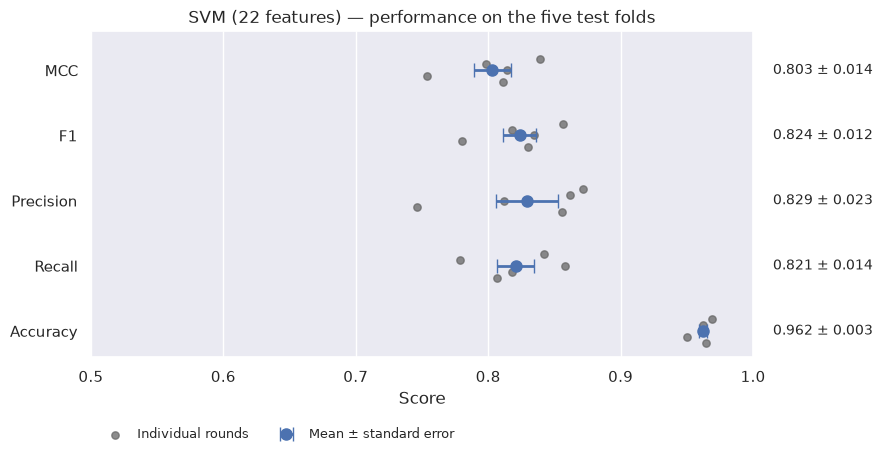

In [26]:
# Mean ± SE and individual-fold points follow 03 section 5.6.
y_positions = np.arange(len(metric_columns))
means = cv_summary.loc[metric_columns, "mean"].to_numpy()
errors = cv_summary.loc[metric_columns, "stderr"].to_numpy()

fig, ax = plt.subplots(figsize=(9, 4.8))
offsets = np.linspace(-0.18, 0.18, n_rounds)
for index, (_, row) in enumerate(cv_per_round.iterrows()):
    ax.scatter(
        row[metric_columns].to_numpy(dtype=float), y_positions + offsets[index],
        s=28, color="0.4", alpha=0.75, zorder=2,
        label="Individual rounds" if index == 0 else None
    )

ax.errorbar(
    means, y_positions, xerr=errors, fmt="o",
    color="C0", markersize=8, capsize=5, linewidth=2,
    label="Mean ± standard error", zorder=3
)
for position, mean_value, error_value in zip(y_positions, means, errors):
    ax.text(
        1.03, position, f"{mean_value:.3f} ± {error_value:.3f}",
        transform=ax.get_yaxis_transform(), va="center", fontsize=10
    )

ax.set_yticks(y_positions, [metric_labels[metric] for metric in metric_columns])
ax.set_ylim(len(metric_columns) - 0.6, -0.6)
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("Score")
ax.set_title("SVM (22 features) — performance on the five test folds")
ax.grid(axis="y", visible=False)
ax.legend(
    loc="upper left", bbox_to_anchor=(0, -0.18),
    ncol=2, frameon=False, fontsize=9
)
fig.tight_layout()

figure_path = figure_dir / "6_3_cv_metrics.pdf"
fig.savefig(figure_path, format="pdf", bbox_inches="tight")
print("Plot saved in:", figure_path)
plt.show()


### 6.4 Feature importance and ranking across folds

**Implemented and executed.** Bars show mean RF importance across the outer-training fits; grey points show the individual fit values. The heatmap reports ranks in the same feature order (1 = highest). PSWM is highlighted in orange where present. All features were retained in all five rounds of this run, so each mean summarizes five recorded importances. These are RF training importances, not SVM attributions or test-set feature effects.

The cell reads this experiment's exported selected-feature table and saves `results/figures/6_4_feature_ranking.pdf`.

**Similar code:** feature importances follow SVM slide 35; the heatmap and PDF conventions follow 03 section 2.3 and main 04 section 4.3.


Plot saved in: results/figures/6_4_feature_ranking.pdf


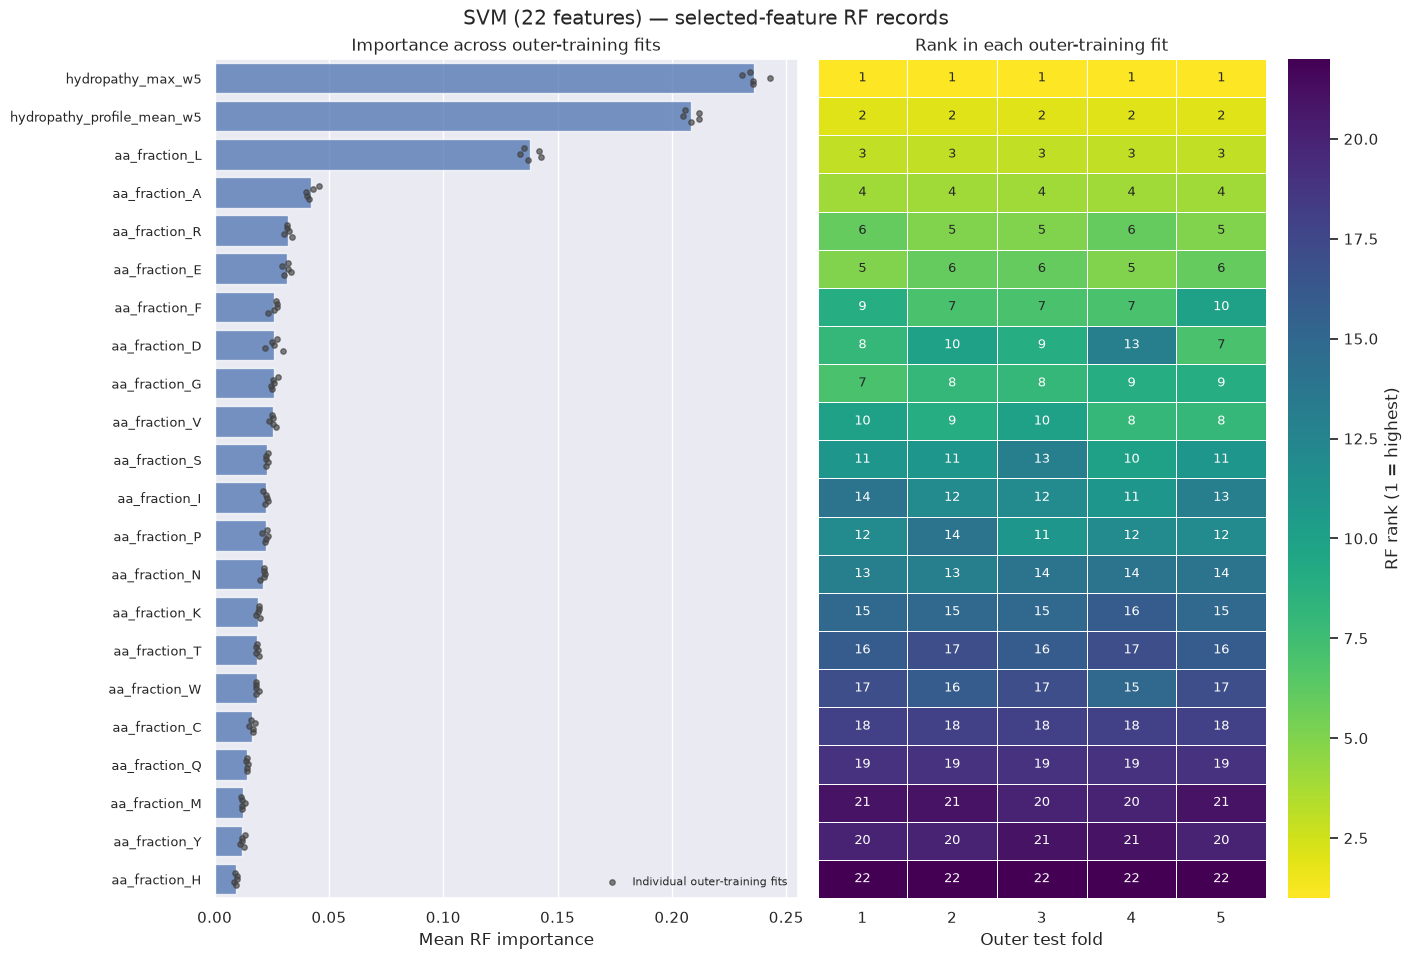

In [27]:
# RF importance follows SVM slide 35; plotting/export follows main 04 and 03.
# Read this experiment's saved records; no model refitting is needed.
rf_records = pd.read_csv(table_dir / "6_2_selected_features.tsv", sep="\t")
importance_by_fold = rf_records.pivot(index="feature", columns="test_fold", values="importance")
rank_by_fold = rf_records.pivot(index="feature", columns="test_fold", values="rank")
mean_importance = importance_by_fold.mean(axis=1).sort_values(ascending=False)
feature_order = mean_importance.index
importance_by_fold = importance_by_fold.loc[feature_order]
rank_by_fold = rank_by_fold.loc[feature_order]

fig, axes = plt.subplots(
    1, 2, figsize=(14, 0.34 * len(feature_order) + 2),
    gridspec_kw={"width_ratios": [1.3, 1]}, layout="constrained"
)
y_positions = np.arange(len(feature_order))
colors = ["C1" if feature == "pswm_score" else "C0" for feature in feature_order]
axes[0].barh(y_positions, mean_importance, color=colors, alpha=0.75)
offsets = np.linspace(-0.16, 0.16, len(importance_by_fold.columns))
for index, fold in enumerate(importance_by_fold.columns):
    axes[0].scatter(
        importance_by_fold[fold], y_positions + offsets[index],
        color="0.25", s=15, alpha=0.65,
        label="Individual outer-training fits" if index == 0 else None
    )
axes[0].set_yticks(y_positions, feature_order, fontsize=9)
axes[0].set_ylim(len(feature_order) - 0.5, -0.5)
axes[0].set_xlabel("Mean RF importance")
axes[0].set_title("Importance across outer-training fits")
axes[0].grid(axis="y", visible=False)
axes[0].legend(loc="lower right", fontsize=8, frameon=False)

sns.heatmap(
    rank_by_fold, ax=axes[1], annot=True, fmt=".0f", annot_kws={"fontsize": 9},
    cmap="viridis_r", vmin=1, vmax=len(feature_order), yticklabels=False,
    linewidths=0.4, cbar_kws={"label": "RF rank (1 = highest)"}
)
axes[1].set_title("Rank in each outer-training fit")
axes[1].set_xlabel("Outer test fold")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", labelrotation=0)
fig.suptitle("SVM (22 features) — selected-feature RF records")

figure_path = figure_dir / "6_4_feature_ranking.pdf"
fig.savefig(figure_path, format="pdf", bbox_inches="tight")
print("Plot saved in:", figure_path)
plt.show()


**Observation.** Maximum hydropathy, mean hydropathy and leucine fraction occupied ranks 1–3 in every outer-training fit. Their mean RF importances were 0.236, 0.209 and 0.138. This is consistent with the hydrophobic N-terminal patterns in the supplementary exploration and 02c. The smaller composition importances do not establish that those fractions contain no useful information.


### 6.5 Pooled classification errors

**Implemented and executed.** The first panel contains the pooled counts from the five held-out folds. The second normalizes each actual-class row to 100%, making missed SP proteins and false-positive NO_SP proteins easier to compare. These row percentages are descriptive pooled rates, not the mean ± SE estimates in 6.1.

The cell reads the saved accession-level predictions and saves `results/figures/6_5_confusion_matrix.pdf`.

**Similar code:** 03 section 5.7 supplies the count-based confusion matrix; we added the row-normalized panel.


Plot saved in: results/figures/6_5_confusion_matrix.pdf


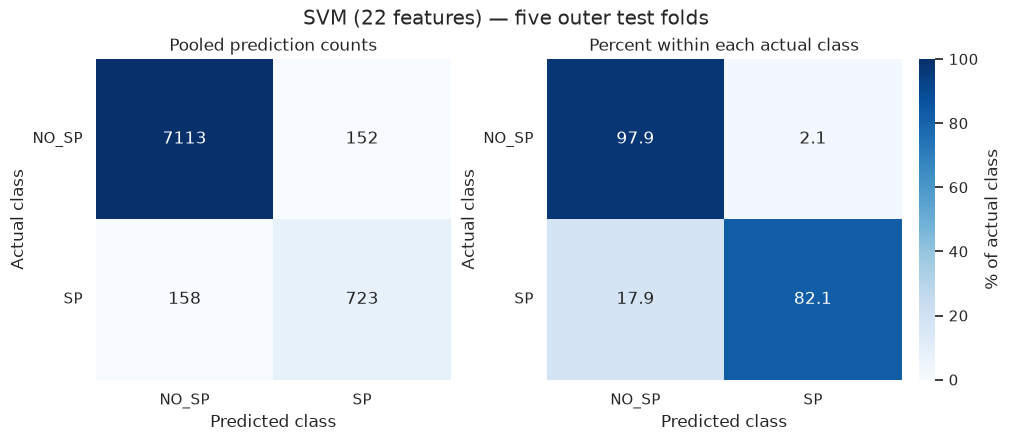

In [28]:
# Count-based confusion plots follow 03 section 5.7.
# Add row percentages so SP/NO_SP error rates can be compared despite class imbalance.
confusion_predictions = pd.read_csv(table_dir / "6_1_cv_predictions.tsv", sep="\t")
confusion_counts = pd.crosstab(
    confusion_predictions["label"], confusion_predictions["prediction"]
).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
confusion_percent = confusion_counts.div(confusion_counts.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3), layout="constrained")
sns.heatmap(
    confusion_counts, ax=axes[0], annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["NO_SP", "SP"], yticklabels=["NO_SP", "SP"]
)
sns.heatmap(
    confusion_percent, ax=axes[1], annot=True, fmt=".1f", cmap="Blues",
    vmin=0, vmax=100, cbar_kws={"label": "% of actual class"},
    xticklabels=["NO_SP", "SP"], yticklabels=["NO_SP", "SP"]
)
axes[0].set_title("Pooled prediction counts")
axes[1].set_title("Percent within each actual class")
for ax in axes:
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.tick_params(axis="y", labelrotation=0)
fig.suptitle("SVM (22 features) — five outer test folds")

figure_path = figure_dir / "6_5_confusion_matrix.pdf"
fig.savefig(figure_path, format="pdf", bbox_inches="tight")
print("Plot saved in:", figure_path)
plt.show()


**Observation.** The pooled predictions contained 723 true positives, 158 false negatives, 152 false positives and 7,113 true negatives. The baseline missed 17.9% of annotated SP proteins and classified 2.1% of NO_SP proteins as SP. The percentage panel makes the missed-positive fraction visible despite the larger negative class. These percentages use pooled counts; the mean fold metrics in 6.1 are calculated separately.


### 6.6 Conclusions

Across the five outer folds, the 22-feature baseline obtained MCC 0.803 ± 0.014 and F1 0.824 ± 0.012. Precision was 0.829 ± 0.023, recall 0.821 ± 0.014 and accuracy 0.962 ± 0.003. Uncertainties are standard errors across folds. MCC ranged from 0.754 to 0.839, with fold 4 giving the lowest value.

Composition and the two hydropathy summaries provided useful SP discrimination, but the baseline retained substantial false-negative and false-positive counts. The dominant RF ranks involved hydropathy and leucine fraction, consistent with a hydrophobic N-terminal signal.

All outer refits used n = 22 and selected all 22 features. Folds 1–4 selected C = 4 and gamma factor = 0.5; fold 5 selected C = 1 and gamma factor = 1. Gamma equals the factor divided by k. These settings were chosen within the fixed 27-candidate grid.

The 31-feature main notebook reached MCC 0.858 ± 0.010 and F1 0.873 ± 0.009, exceeding this baseline in all five folds. Adding PSWM to the baseline reached MCC 0.850 ± 0.010 and F1 0.866 ± 0.008, also improving both metrics in every fold. These comparisons support the usefulness of the richer descriptors and the supervised PSWM score for the evaluated procedures, without identifying which individual additional descriptor explains the difference.

This experiment is a useful reduced-feature baseline. All 8,146 training proteins were predicted once using held-out outer folds. The independent benchmarking split remains reserved, and these descriptive fold comparisons are not tests of statistical significance.

These nested-CV scores evaluate the complete feature extraction, selection and classification procedure. The settings selected in the five outer rounds are not a final production-model configuration. Selecting and fitting that final model is a separate stage.
